# Практическое задание 2. Диффузионные модели


## Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи).

Сдавать задание после указанного жёсткого срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи !!ВАЖНО!!!
Задания сдаются через систему google classroom. Посылка должна содержать:
* Ноутбук ddpm_hw_bmmo-Username.ipynb

Username &ndash; ваша фамилия и имя на латинице именно в таком порядке

<p style="color:#de3815;font-size:25px;">
Напоминание об оформлении и выполнении ноутбука
</p>

* Все строчки должны быть выполнены. Нужно, чтобы output команды можно было увидеть, не запуская ячейки (кроме редких случаев, когда необходимо намеренно скрыть ненужный output, про такие случаи желательно писать пояснения в тексте). **В противном случае -1 балл**
* При оформлении ДЗ нужно пользоваться данным файлом в качестве шаблона. Не нужно удалять и видоизменять написанный код и текст, если явно не указана такая возможность. **В противном случае -1 балл**
* В anytask обязательно нужно прикреплять отдельно файл с расширением ipynb (не в архиве, а именно отдельно). Если необходимо отправить еще какие-то файлы, то вынесите их в отдельный архив (если файлов много) и пришлите. **В противном случае -0.5 балла*

# В этом задании необходимо будет дореализовать ключевые формулы для обучения дискретной диффузионной модели из статьи DDPM.

[Статья DDPM](https://arxiv.org/pdf/2006.11239.pdf)


---
Для выполнения домашнего задания достаточно использовать Google Colab.

In [1]:
!python3 -V
import torch


print(f'torch.__version__: {torch.__version__}')

Python 3.13.15
torch.__version__: 2.11.0+cu130


In [4]:
!pip3 install wandb comet_ml==3.55.0 -q     #установка логгеров
!pip3 install torch_ema denoising_diffusion_pytorch

В задании по умолчанию выбран логгер wandb, вы можете, также использовать логгер comet_ml. В Anytask помимо ноутбука **надо будет сдать ссылку на публичный проект** в одном из этих логгеров.

In [5]:
import torch
import numpy as np
import random


def set_global_seed(seed: int) -> None:
    """
    Set global seed for reproducibility.
    """

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    random.seed(seed)
    np.random.seed(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_global_seed(42)

# Датасет

In [6]:
import os
import numpy as np
import PIL

from tqdm import tqdm
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, Dataset
from typing import Generator, Tuple, Dict, Optional, Union
from torch import Tensor
from cv2 import resize


def preprocess_image(image: "PIL.Image") -> np.ndarray:
    image = np.array(image, dtype=np.uint8)
    image = resize(image, (32, 32))
    return np.array(image, dtype=np.float32) / 127.5 - 1


def postprocess_image(image: torch.Tensor) -> torch.Tensor:
    # convert values to [0; 255]
    image = image.cpu().detach()
    image = (image + 1) * 127.5
    image = torch.clip(image, 0, 255)
    return image


class MnistDataset(Dataset):
    def __init__(self, train: bool = True):
        super().__init__()
        self.mnist = MNIST(
            'data',
            train=train,
            download=True
        )

    def __len__(self) -> int:
        return len(self.mnist)

    def __getitem__(self, index: int) -> Dict[str, Tensor]:
        image, target = self.mnist[index]
        image = preprocess_image(image)
        target = int(target)
        return {
            "images": Tensor(image)[None],
            "targets": target
        }

In [7]:
def dict_to_device(dct: Dict[str, Tensor], device: torch.device) -> Dict[str, Tensor]:
    return {k: v.to(device) for k, v in dct.items()}


def get_train_images_generator(
    batch_size: int = 128,
    num_workers: int = 0,
    shuffle: bool = True,
    drop_last: bool = True
) -> Generator[Dict[str, Tensor], None, None]:
    dataset = MnistDataset(train=True)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        num_workers=num_workers,
        shuffle=shuffle,
        drop_last=drop_last
    )
    while True:
        yield from loader

In [8]:
def check_generator(batch_size: int = 128):
    generator = get_train_images_generator(batch_size)
    batch_dict = next(generator)
    assert(batch_dict['images'].shape == (batch_size, 1, 32, 32), batch_dict['images'].shape)
    assert(batch_dict['targets'].shape == (batch_size,), batch_dict['targets'].shape)

check_generator(131)

<>:4: SyntaxWarning: assertion is always true, perhaps remove parentheses?
<>:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
<>:4: SyntaxWarning: assertion is always true, perhaps remove parentheses?
<>:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
/tmp/ipykernel_464/2113533935.py:4: SyntaxWarning: assertion is always true, perhaps remove parentheses?
  assert(batch_dict['images'].shape == (batch_size, 1, 32, 32), batch_dict['images'].shape)
/tmp/ipykernel_464/2113533935.py:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
  assert(batch_dict['targets'].shape == (batch_size,), batch_dict['targets'].shape)
100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 463kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.43MB/s]


# DDPM's dynamic (5 баллов)



В `get_coeffs_primities` (2 pts) необходимо в возвращаеый словарь добавить рассчет коэффицентов, при помощи которых вы сможете реализовать семплирование из распределений $q(x_t | x_0), q(x_t | x_{t+1}, x_0), p(x_t | x_{t + 1})$.

Например:
- $\alpha_t = 1 - \beta_t$
- $\bar{\alpha_t} = \prod_{t=1}^{T} \alpha_t$
- $\sqrt{\bar{\alpha_t}}$
- ...
- любые коэффиценты, которые помогут вам рассчитать коэффиценты в $q(x_t | x_0), q(x_t | x_{t+1}, x_0), p(x_t | x_{t + 1})$

`extract_values_from_times` - по батчу с целочислненными временами выдает батч коэфиицентов в нужном шейпе для перемножения с батчом картинок


In [9]:
from torch import nn


def get_coeffs_primitives(
    T: int = 1000,
    beta_min: float = 1e-4,
    beta_max: float = 2e-2,
) -> Dict[str, Tensor]:
    """
    output: Dict[str, Tensor]
      {
        "a": b
      }
    ---
    b.shape == (T,)
    """
    betas = torch.linspace(beta_min, beta_max, T).float()
    alphas = 1 - betas

    sqrt_alphas = torch.sqrt(alphas)
    alphas_hat = torch.cumprod(alphas, dim=0)

    alphas_hat_prev = torch.cat([torch.FloatTensor([1.]), alphas_hat[:-1]])

    # YOUR CODE GOES HERE

    return {
        "betas": betas,
        "alphas": alphas,
        "sqrt_alphas_hat": sqrt_alphas_hat,
        ...
    }
    


def extract_values_from_times(values: Tensor, times: torch.LongTensor) -> Tensor:
    values = values[times]
    return values[:, None, None, None]


## Релизуйте DDPMDynamic (3 балла)

`DDPMDynamic`:
- `__init__` - получаем коэффиценты, добавляем их в класс, как атрибуты, чтобы доставать их по имени без использования словаря
- `sample_from_posterior_q(x_t: FloatTensor, x_0: FloatTensor, t: LongTensor)` - $ x_{t-1} \sim q(x_{t-1} | x_{t}, x_0) $
- `forward` - $ x_{t} \sim q(x_t | x_0) $

In [10]:
class DDPMDynamic(nn.Module):
    def __init__(
        self,
        T: int = 1000,
        beta_min: float = 1e-4,
        beta_max: float = 2e-2,
    ):
        super().__init__()
        self.T = T

        coeffs_primitives = get_coeffs_primitives(T, beta_min, beta_max)

        for name, tensor in coeffs_primitives.items():
            self.register_buffer(name, tensor)

    def sample_time_on_device(self, batch_size: int = 1, device: torch.device = torch.device('cpu')):
        return torch.randint(0, self.T, (batch_size,), device=device)

    def sample_from_posterior_q(
        self,
        x_t: Tensor,
        x_0: Tensor,
        t: torch.LongTensor
    ) -> Tensor:
        
        # YOUR CODE GOES HERE
        
        pass

    def get_x_zero(
        self,
        x_t: Tensor,
        eps: Tensor,
        t: torch.LongTensor
    ) -> Tensor:
        sqrt_alphas_hat = extract_values_from_times(self.sqrt_alphas_hat, t)
        sqrt_1m_alphas_hat = extract_values_from_times(self.sqrt_1m_alphas_hat, t)

        x_0 = (x_t - sqrt_1m_alphas_hat * eps) / sqrt_alphas_hat
        return x_0

    def forward(self, batch: Dict[str, Tensor]) -> Dict[str, Tensor]:
        """
            Dict:
                x_0 - clean_image
                t - time (int \in [0; T - 1])
                eps - Optional[corresponding noise]
        Returns:
            Dict:
                x_t - noised_sample
                eps - corresponding noise
        """
        x_0 = batch['x_0']
        t = batch['time']

        # YOUR CODE GOES HERE

        return {
            "x_t": ...,
            "eps": ...
        }


<>:77: SyntaxWarning: invalid escape sequence '\i'
<>:77: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_464/3899408528.py:77: SyntaxWarning: invalid escape sequence '\i'
  t - time (int \in [0; T - 1])


In [11]:
def check_ddpm_dynamic():
    dynamic = DDPMDynamic()
    device = torch.device('cuda:0')
    dynamic.to(device)
    times = dynamic.sample_time_on_device(10, device)
    assert times.device == device, f'{times.device}, {device}'
    assert times.shape == (10,)

check_ddpm_dynamic()

## Реализуйте генерация (1.5 балла)

`Sampler`/DDPM's cycle:
- `single_step` - необходимо просемплировать $x_{t-1} \sim p(x_{t-1}|x_t)$
- `sample` - весь процесс обхода по марковской цепочки семплирования

In [12]:
from tqdm.auto import trange


class Sampler(nn.Module):
    def __init__(
        self,
        ddpm: nn.Module,
        dynamic: DDPMDynamic
    ):
        super().__init__()
        ddpm.eval()
        self.ddpm = ddpm
        self.dynamic = dynamic

    @torch.no_grad()
    def single_step(self, x_t, t):
        
        # YOUR CODE GOES HERE
        
        pass

    @torch.no_grad()
    def sample(
        self,
        shape: Tuple[int, int, int, int],
        device: torch.device = torch.device('cpu'),
        verbose: bool = False
    ) -> Tensor:
        self.ddpm.eval()
        x_t = torch.randn(shape, device=device)
        batch_size = shape[0]

        bar = trange if verbose else range
        for t in bar(self.dynamic.T - 1, -1, -1):
            t_tensor = torch.ones(batch_size, dtype=torch.int64, device=device) * t
            x_t = self.single_step(x_t, t_tensor)
        return x_t


## Обучение (1.5 балла)

При помощи примитивов сверху реализовать обучение DDPM. Алгоритм обучения представлен ниже.

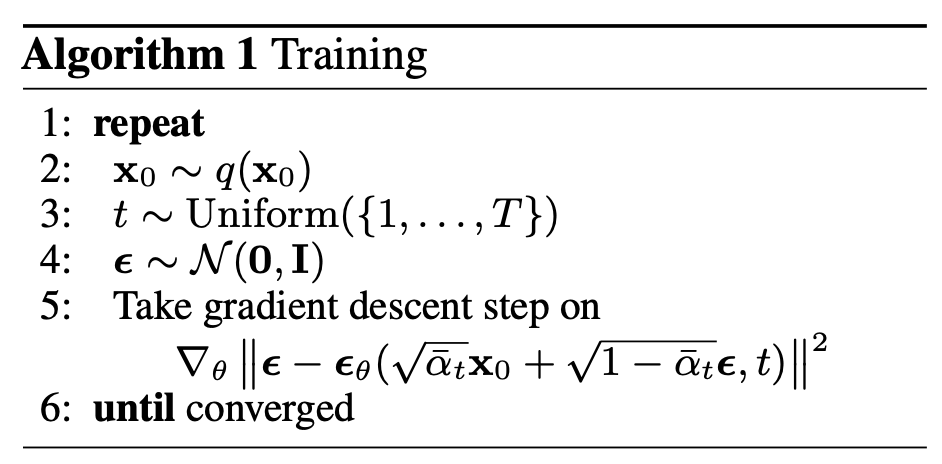


`DiffusionTrainer`:
- `calc_loss(clean_images: FloatTensor)` - необходимо внутри метода просемплировать время, далее просемплировать $x_t$, обработать батч, рассчитать лосс для обучения

In [24]:
# Использовать если на GoogleColab, иначе подставить свой api
# from google.colab import userdata

import wandb
import comet_ml

USE_COMET = False

def logger_start(project_name, run_name, use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.start(
            api_key=userdata.get('COMET_API_KEY'),
            project_name=project_name,
            online=True
        )
        experiment.set_name(run_name)
    else:
        wandb.init(
          project=project_name,
          name=run_name,
          mode='online'
        )

def log_metrics(d, step, use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.log_metrics(d, step=step)
    else:
        wandb.log(d, step=step)

def log_images(img, img_name, step, use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.log_image(
          image_data=img,
          name=img_name,
          step=step
        )
    else:
        wandb.log({img_name: wandb.Image(img)}, step=step)

def logger_end(use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.end()
    else:
        wandb.finish()

In [25]:
from torch_ema import ExponentialMovingAverage
import math
import torchvision


class DiffusionTrainer:
    def __init__(
        self,
        ddpm: nn.Module,
        dynamic: DDPMDynamic,
        device: torch.device = torch.device('cpu')
    ):
        self.ddpm = ddpm
        self.dynamic = dynamic

        self.dynamic.to(device)
        self.ddpm.to(device)

        self.sampler = Sampler(ddpm, dynamic)
        self.sampler.to(device)

        self.ema = ExponentialMovingAverage(ddpm.parameters(), decay=0.999)

        self.device = device


        self.optimizer = torch.optim.AdamW(
            self.ddpm.parameters(),
            lr=2e-4,
            weight_decay=1e-2
        )

        self.step = 0

    def switch_to_ema(self) -> None:
        self.ema.store(self.ddpm.parameters())
        self.ema.copy_to(self.ddpm.parameters())

    def switch_back_from_ema(self) -> None:
        self.ema.restore(self.ddpm.parameters())

    def calc_loss(self, x_0: torch.Tensor) -> torch.Tensor:
        
        # YOUR CODE GOES HERE
        
        pass

    def log_metric(self, metric_name: str, loader_name: str, value: Union[float, torch.Tensor]):
        log_metrics({f'{metric_name}/{loader_name}': value}, step=self.step)

    def log_image(self, metric_name: str, loader_name: str, value: torch.Tensor):
        log_images(value, f'{metric_name}/{loader_name}', step=self.step)

    def optimizer_logic(self, loss: torch.Tensor) -> None:
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        self.ema.update(self.ddpm.parameters())

    def train(
            self,
            train_generator: Generator[Dict[str, Tensor], None, None],
            total_iters: int = 1000,
            project_name: str = 'discrete_time_ddpm',
            experiment_name: str = 'mnist_baseline'
        ) -> None:
        logger_start(project_name=project_name, run_name=experiment_name)
        self.ddpm.train()

        for iter_idx in trange(1, 1 + total_iters):
            self.step = iter_idx

            batch = next(train_generator)
            batch = dict_to_device(batch, device=self.device)

            loss = self.calc_loss(x_0=batch['images'])
            self.log_metric('mse', 'train', loss)

            self.optimizer_logic(loss)

            if iter_idx % 1000 == 0:
                self.snapshot()

        self.ddpm.eval()
        self.switch_to_ema()

        logger_end()

    @torch.no_grad()
    def sample_images(
            self, batch_size: int,
            verbose: bool = False
    ) -> torch.Tensor:
        x_pred = self.sampler.sample((batch_size, 1, 32, 32), self.device, verbose)
        x_pred = postprocess_image(x_pred)
        return x_pred

    @torch.no_grad()
    def snapshot(self) -> None:
        prev_mode = self.ddpm.training

        self.ddpm.eval()
        self.switch_to_ema()

        images = self.sample_images(100).cpu()
        nrow = 10
        grid = torchvision.utils.make_grid(images, nrow=nrow).permute(1, 2, 0)
        grid = grid.data.numpy().astype(np.uint8)
        self.log_image('images', 'from_noise', grid)

        self.switch_back_from_ema()
        self.ddpm.train(prev_mode)

In [26]:
from denoising_diffusion_pytorch import Unet

set_global_seed(42)

ddpm = Unet(
    dim=64,
    dim_mults=(1, 2, 4, 4),
    channels=1,
    flash_attn=True
)

In [27]:
device = torch.device('cuda:0')

In [28]:
trainer = DiffusionTrainer(
    ddpm,
    DDPMDynamic(),
    device
)

In [29]:
generator = get_train_images_generator(128)

Если у вас будут проблемы с wandb, то можете перейти в comet_ml. **Не оставляйте свой API ключ в сданном ноутбуке!**

In [31]:
# Время обучения около 45 минут

trainer.train(
    generator,
    total_iters=5000
)

Вы обучили большую модель, самое важное ее сохранить и не потерять!!! Мы будем использовать ema сглаженные веса, так как на них обычно достигается лучше качество генерации. Подробнее про сглаживание можно почитать в статье [Averaging Weights Leads to Wider Optima and Better Generalization](https://arxiv.org/abs/1803.05407).

In [32]:
trainer.switch_to_ema()
torch.save(ddpm.state_dict(), "./pretrained_ddpm_checkpoint.pth")

Если вы используете облачные сервисы, то лучше сохранить на устройство локально, так как при перезапуске сессий очень часто пропадают файлы!

# Безусловная генерация неплохих изображений  (1 балл)

In [34]:
from matplotlib import pyplot as plt
import math

@torch.inference_mode()
def sample_images(
    sampler: Sampler, batch_size: int = 100,
    device = torch.device('cpu'),
    verbose: bool = True
):
    images = sampler.sample((batch_size, 1, 32, 32), device, True)
    images = postprocess_image(images)
    images = images.cpu()
    nrow = int(math.ceil(math.sqrt(batch_size)))
    grid = torchvision.utils.make_grid(images, nrow=nrow).permute(1, 2, 0)
    grid = grid.data.numpy().astype(np.uint8)
    return grid

grid = sample_images(trainer.sampler, 100, trainer.device)

plt.imshow(grid)
plt.show()

# Опишите ваши выводы/результаты: (1 балл)

-
-
-

# Оценка качества (3 балла)

Выше мы обучили модель и визуально оценили качество сэмплов, теперь возникает вопрос: как получить объективную метрику качества модели. Один из вариантов получения объективной оценки &ndash; ответить на вопрос: насколько распределение генерируемых моделью изображений "похоже" на распределение истинных изображений.

Таким образом, мы свели задачу объективной оценки к нахождению схожести между распределениями.

Существует множество способов оценки схожести распределений. В области computer vision популярным способом является **FID (Fréchet Inception Distance)**. Данная метрика вычисляет квадрат \textit{расстояния Вассерштейна-$2$} между распределениями активаций некоторой обученной свёрточной модели.

Подробнее смотрите в статье [GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium](https://arxiv.org/abs/1706.08500).

Более конкретно, положим, что есть два множества изображений, которые мы хотим сравнить:
\begin{equation}
    A = \{a_{i}\}, B = \{b_{j}\}, \quad a_{i}, b_{i} \in \mathcal{I}.
\end{equation}

Рассмотрим глубокую свёрточную модель для извлечения векторных представлений:
\begin{equation}
    M: \mathcal{I} \rightarrow \mathbb{R}^{d}.    
\end{equation}

Предположим, что
\begin{align}
    &M(a) \sim \mathcal{N}(\mu_{A}, \Sigma_{A}),\\
    &M(b) \sim \mathcal{N}(\mu_{B}, \Sigma_{B}).
\end{align}

Предположение метрики FID утверждает, что если распределения $M(a)$, $M(b)$ близки друг к другу, то и множества изображений $A$, $B$ похожи. Данное утверждение было проверено эмпирически.

В качестве меры близости между распределениями используется *расстояние Вассерштейна-$2$*:
\begin{equation}
    \textbf{FID} = \mathcal{W}^2_{2}(\mathcal{N}(\mu_{A}, \Sigma_{A}), \mathcal{N}(\mu_{B}, \Sigma_{B})) = ||\mu_{A} - \mu_{B}||_{2}^{2} + \text{Tr}\Big( \Sigma_{A} + \Sigma_{B} - 2 \sqrt{\Sigma_{A} \Sigma_{B}} \Big). \tag{1}
\end{equation}

Стандартным выбором для модели выделения признаков $M$ является **Inception V3**. В частности, берутся активации после Average Pooling, что даёт размерность признакового вектора $d = 2048$.

Для подсчёта метрик обычно фиксируют некоторое количество сгенерированных изображений. Типичный размер $|A| = 5000$ или $50000$.

В этом задании вам предлагается получить график зависимости FID от размера выборки. Генерировать $50000$ изображений займет много времени, поэтому вам необходимо будет один раз сгенерировать $5000$ изображений и взять $K = [200, 500, 1000, 2000, 3000, 4000, 5000]$ изображений при подсчете метрики.

Для удобства вы можете брать первые $K$ изображений.

Загрузим модель для подсчёта активаций. Уберём последний линейный слой и дропаут для получения активаций после Average Pool:

In [35]:
from torchvision import transforms

In [36]:
inception_model = torch.hub.load(
    'pytorch/vision:v0.10.0', 'inception_v3',
    weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1
)
inception_model.dropout = torch.nn.Identity()
inception_model.fc = torch.nn.Identity()
inception_model.eval()

inception_transform = transforms.Compose([
    transforms.Resize(299),
    transforms.CenterCrop(299),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /root/.cache/torch/hub/v0.10.0.zip
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 160MB/s] 


Реализуйте датасет обёртку для обработки папки с изображениями:

In [54]:
import glob # glob.glob(template) помогает искать файлы по template

class ImagesDataset(Dataset):
    def __init__(self, template: str, transform):
        """
        :param str template: Path to the images
        :param Callable[PIL.Image.Image, torch.Tensor] transform: Image transform
        """
        super().__init__()

        self.paths = sorted(glob.glob(template))
        
        # YOUR CODE GOES HERE
        ...

    def __len__(self) -> int:
        """
        Number of images
        :rtype: int
        """
        # YOUR CODE GOES HERE
        ...

    def __getitem__(self, idx: int) -> torch.Tensor:
        """
        :param int idx: Image Id
        :return:
        :rtype: torch.Tensor
        """
        # Inception ожидает RGB изображения
        image = PIL.Image.open(self.paths[idx]).convert("RGB")
        # YOUR CODE GOES HERE
        return ...

Теперь реализуем функцию для подсчёта активаций для всех изображений в заданной директории:

In [55]:
@torch.inference_mode()
def get_activations(
    template: str, model: torch.nn.Module, transform, batch_size: int, device: torch.device
) -> np.ndarray:
    """Compute activations for all images specified by template
    :param str template: Path to the images
    :param torch.nn.Module model: Model that compute activations
    :param Callable[PIL.Image.Image, torch.Tensor] transform: Image transform
    :param int batch_size: Batch size to perform a forward pass
    :param torch.device device: Target device
    :return: 2D array of activations
    :rtype: np.ndarray
    """
    model.to(device)

    dataset = ImagesDataset(template, transform=transform)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    features = []
    for images in tqdm(
        dataloader, total=len(dataloader), desc=f'Compute activations for the {template}'
    ):
        images = images.to(device)
        output = model(images).cpu()
        features.append(output)

    return torch.cat(features, dim=0).numpy()

Выгрузим MNIST в формате `.png`.

In [56]:
def extract_dataset(folder: str, count: int = 5000):

    os.makedirs(folder, exist_ok=True)
    data = MnistDataset()

    for i in tqdm(range(count)):
        img = data[i]['images']
        img = postprocess_image(img)
        img = img.cpu().permute(1, 2, 0).numpy().astype('uint8')

        file_name = os.path.join(folder, f'img_{i:05d}.png')
        PIL.Image.fromarray(img[:, :, 0], 'L').save(file_name)

In [57]:
mnist_images_path = './mnist_images/'
extract_dataset('./mnist_images/')

  0%|          | 0/5000 [00:00<?, ?it/s]/tmp/ipykernel_464/1295096041.py:12: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  PIL.Image.fromarray(img[:, :, 0], 'L').save(file_name)
100%|██████████| 5000/5000 [00:03<00:00, 1352.61it/s]


In [61]:
assert len(glob.glob("./mnist_images/*.png")) == 5000

In [62]:
activations_real = get_activations(
    mnist_images_path + "*.png", inception_model, inception_transform, batch_size=256, device=device
)

In [63]:
assert activations_real.shape == (5000, 2048)
assert np.allclose(np.linalg.norm(activations_real), 1380.5614, atol=1.0)

Теперь реализуем подсчёт FID по формуле (1).

In [64]:
import scipy

def compute_fid(activations_real: np.ndarray, activations_fake: np.ndarray) -> float:
    """
    :param np.ndarray activations_real: Activations for the real images
    :param np.ndarray activations_fake: Activations for the fake images
    """

    # YOUR CODE GOES HERE
    ...

    
    # hint: scipy.linalg.sqrtm
    fid = ...

    return fid

In [68]:
assert np.allclose(compute_fid(activations_real, activations_real), 0.0)
assert np.allclose(compute_fid(activations_real, np.ones((13, 2048))), 1291.0, atol=1.0)
assert np.allclose(compute_fid(activations_real, np.zeros((13, 2048))), 381.0, atol=1.0)

Теперь перейдем к генерации изображений с помощью диффузионной модели.

In [69]:
set_global_seed(42)
device = torch.device('cuda:0')
ddpm = Unet(
    dim=64,
    dim_mults=(1, 2, 4, 4),
    channels=1,
    flash_attn=True
).to(device)

Загрузим из чекпоинта или лучше с облака.

In [70]:
checkpoint = torch.load("./pretrained_ddpm_checkpoint.pth")

ddpm.load_state_dict(checkpoint)
ddpm.eval()

Unet(
  (init_conv): Conv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
  (time_mlp): Sequential(
    (0): SinusoidalPosEmb()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (downs): ModuleList(
    (0): ModuleList(
      (0-1): 2 x ResnetBlock(
        (mlp): Sequential(
          (0): SiLU()
          (1): Linear(in_features=256, out_features=128, bias=True)
        )
        (block1): Block(
          (proj): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (norm): RMSNorm()
          (act): SiLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (block2): Block(
          (proj): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (norm): RMSNorm()
          (act): SiLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (res_conv): Identity()
      )
      (2): Line

Мы знаем, что для генерации батча нам нужно будет сделать $T=1000$ вызовов нейронной сети. Замерим время одного прогона со стандартным `batch_size`, который помещается в память на облачных сервисах. Мы будем делать не совсем правильные замеры, так как нам важно понять порядок. Для правильных замеров нужно сделать прогрев устройства и усреднять время по нескольким замерам.

In [71]:
import time

In [80]:
bs = 128
x_dummy = torch.ones((bs, 1, 32, 32)).float().cuda()
t_dummy = torch.ones(bs, dtype=torch.int64, device=device)

with torch.inference_mode():
    t_s = time.time()
    _ = ddpm(x_dummy, t_dummy)
    torch.cuda.synchronize()
    t_e = time.time()
dt = t_e - t_s
print(f"Время одного вызова Unet с batch_size={bs}: {dt}")
print(f"На генерацию потребуется примерно: {(dt * 1000 * 5000 // bs) // 60} минут")

Время одного вызова Unet с batch_size=128: 0.17363977432250977
На генерацию потребуется примерно: 113.0 минут


Обратите внимание, что не всегда если у вас осталась свободная память надо её занимать. Так как вы не получите ускорения если у вас уже полная утилизация GPU. Если у вас нет свободных воркеров, то увеличение `batch_size` увеличит время инференса.

Однако, мы можем чуть ускорить код с помощью [Automatic Mixed Precision](https://docs.pytorch.org/tutorials/recipes/recipes/amp_recipe.html).

In [88]:
with torch.inference_mode():
    t_s = time.time()
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        _ = ddpm(x_dummy, t_dummy)
    torch.cuda.synchronize()
    t_e = time.time()
dt = t_e - t_s
print(f"Время одного вызова Unet с batch_size={bs}: {dt}")
print(f"На генерацию потребуется примерно: {(dt * 1000 * 5000 // bs) // 60} минут")

Время одного вызова Unet с batch_size=128: 0.12854743003845215
На генерацию потребуется примерно: 83.0 минут


Можно ещё скомпилировать Unet c помощью `torch.compile`. Первый запуск будет долгий, кроме того, он потребует в дальнейшем использовать функцию аналогично как при компиляции.

In [ ]:
ddpm_compile = torch.compile(ddpm)

In [110]:
with torch.inference_mode():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        _ = ddpm_compile(x_dummy, t_dummy) # компиляция занимает около 2 минут
    t_s = time.time()
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        _ = ddpm_compile(x_dummy, t_dummy)
    torch.cuda.synchronize()
    t_e = time.time()
dt = t_e - t_s
print(f"Время одного вызова Unet с batch_size={bs}: {dt}")
print(f"На генерацию потребуется примерно: {(dt * 1000 * 5000 // bs) // 60} минут")

Время одного вызова Unet с batch_size=128: 0.11589932441711426
На генерацию потребуется примерно: 75.0 минут


Если вы считаете на Google Colab и у вас около 80 минут, то дальше будет быстрее, так как устройство прогреется и генерация 128 изображений будет примерно 50 секунд. Тогда вам потребуется около 35 минут на генерацию 5000 изображений.

In [111]:
trainer = DiffusionTrainer(
    ddpm_compile,
    DDPMDynamic(),
    device
)

Реализуем вспомогательную функцию для генерации изображений и сохранения их в заданную директорию:

In [112]:
@torch.inference_mode()
def gen_imgs(
    sampler: Sampler, folder: str,
    device = torch.device('cuda:0'),
    count: int = 5000, batch_size: int = 100, seed: int = 42
):

    set_global_seed(seed)
    os.makedirs(folder, exist_ok=True)
    iter_num = count // batch_size + int(count % batch_size > 0)

    for _ in tqdm(range(iter_num)):

        already_sampled = len(os.listdir(folder))
        bs = min(batch_size, count - already_sampled)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            images = sampler.sample((bs, 1, 32, 32), device, True)
        images = postprocess_image(images)
        images = images.cpu().permute(0, 2, 3, 1).numpy().astype('uint8')

        for i in range(images.shape[0]):
            index = already_sampled + i

            file_name = os.path.join(folder, f'img_{index:05d}.png')
            PIL.Image.fromarray(images[i, :, :, 0], 'L').save(file_name)

In [ ]:
# Долгая функция занимает на Google Colab около 35 минут
gen_imgs(trainer.sampler, "./mnist_gen_img", batch_size=bs)

In [ ]:
activations_fake = get_activations(
    "./mnist_gen_img/*.png",
    inception_model, inception_transform, batch_size=256, device=device
)

Теперь, можно вычислить FID:

In [ ]:
compute_fid(activations_real, activations_fake)

In [ ]:
fids = []
images_count = [200, 500, 1000, 2000, 3000, 4000, 5000]
for image_count in images_count:
    fid = compute_fid(activations_real[:image_count], activations_fake[:image_count])
    fids.append(fid)

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))

ax.plot(images_count, fids, marker='o')
ax.grid(True)

ax.set_xlabel('Images count')
ax.set_title('FID')

fig.tight_layout()
plt.show()

Ваши выводы:

-

*Без выводов задание не будет засчитано.*

### Обратная связь по заданию:

**Ваш ответ здесь**

### Использовали ли вы LLM? Если да, то как именно?

**Ваш ответ здесь**